In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
test_data = pd.read_csv("../dataset/test_data.csv")

X_test = test_data["text"]
y_test = test_data["label"]

print("Testing samples:", len(test_data))

Testing samples: 8936


In [3]:
tfidf = joblib.load(
    "../model/tfidf_vectorizer.pkl"
)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF test data shape:", X_test_tfidf.shape)

TF-IDF test data shape: (8936, 50000)


In [4]:
lr_model = joblib.load(
    "../model/logistic_regression_model.pkl"
)

nb_model = joblib.load(
    "../model/naive_bayes_model.pkl"
)

svm_model = joblib.load(
    "../model/svm_model.pkl"
)

rf_model = joblib.load(
    "../model/random_forest_model.pkl"
)

print("All models loaded successfully!")

All models loaded successfully!


In [5]:
lr_predictions = lr_model.predict(X_test_tfidf)

nb_predictions = nb_model.predict(X_test_tfidf)

svm_predictions = svm_model.predict(X_test_tfidf)

rf_predictions = rf_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [6]:
evaluation_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM",
        "Random Forest"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, svm_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    
    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, nb_predictions),
        precision_score(y_test, svm_predictions),
        precision_score(y_test, rf_predictions)
    ],
    
    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, nb_predictions),
        recall_score(y_test, svm_predictions),
        recall_score(y_test, rf_predictions)
    ],
    
    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, nb_predictions),
        f1_score(y_test, svm_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

evaluation_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.993062,0.989691,0.995757,0.992714
1,Naive Bayes,0.965533,0.960225,0.967468,0.963833
2,Linear SVM,0.998321,0.997411,0.999057,0.998233
3,Random Forest,0.996643,0.995763,0.997171,0.996466


In [7]:
evaluation_results[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
] = evaluation_results[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].round(4)

evaluation_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9931,0.9897,0.9958,0.9927
1,Naive Bayes,0.9655,0.9602,0.9675,0.9638
2,Linear SVM,0.9983,0.9974,0.9991,0.9982
3,Random Forest,0.9966,0.9958,0.9972,0.9965


<Figure size 1000x600 with 0 Axes>

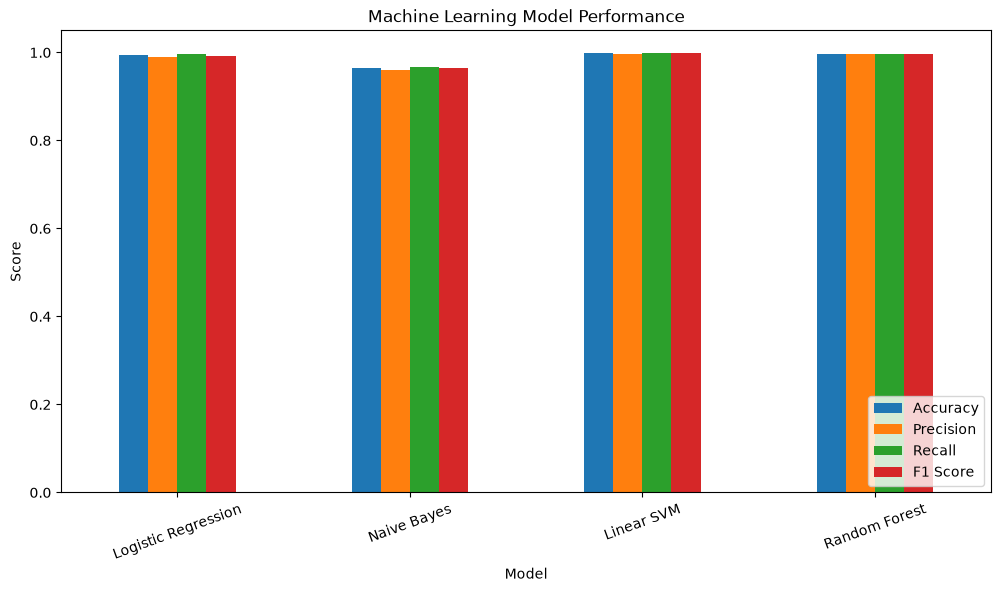

In [8]:
plt.figure(figsize=(10, 6))

evaluation_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")

plt.show()

In [9]:
print("LOGISTIC REGRESSION")
print("=" * 60)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Fake", "Real"]
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

        Fake       1.00      0.99      0.99      4694
        Real       0.99      1.00      0.99      4242

    accuracy                           0.99      8936
   macro avg       0.99      0.99      0.99      8936
weighted avg       0.99      0.99      0.99      8936



In [10]:
print("NAIVE BAYES")
print("=" * 60)

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=["Fake", "Real"]
    )
)

NAIVE BAYES
              precision    recall  f1-score   support

        Fake       0.97      0.96      0.97      4694
        Real       0.96      0.97      0.96      4242

    accuracy                           0.97      8936
   macro avg       0.97      0.97      0.97      8936
weighted avg       0.97      0.97      0.97      8936



In [11]:
print("LINEAR SVM")
print("=" * 60)

print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["Fake", "Real"]
    )
)

LINEAR SVM
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4694
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8936
   macro avg       1.00      1.00      1.00      8936
weighted avg       1.00      1.00      1.00      8936



In [12]:
print("RANDOM FOREST")
print("=" * 60)

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Fake", "Real"]
    )
)

RANDOM FOREST
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4694
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8936
   macro avg       1.00      1.00      1.00      8936
weighted avg       1.00      1.00      1.00      8936



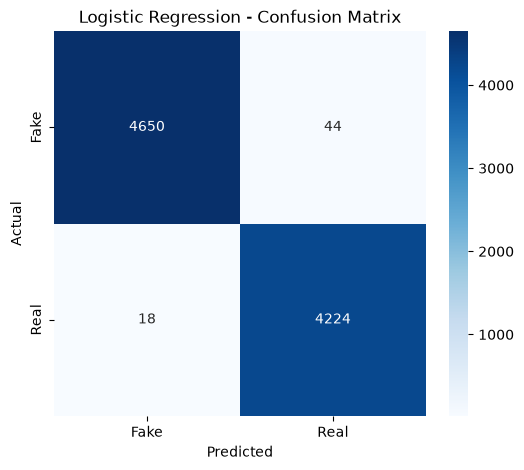

In [13]:
cm_lr = confusion_matrix(
    y_test,
    lr_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

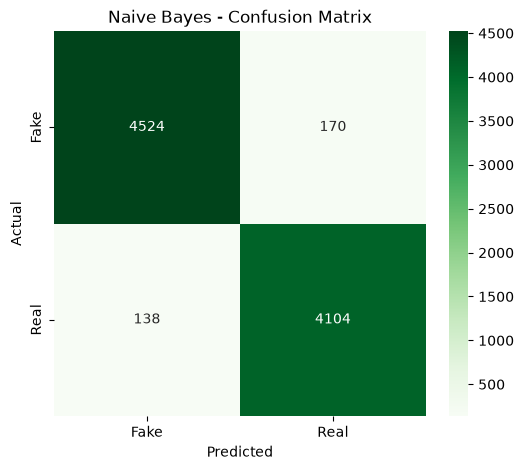

In [14]:
cm_nb = confusion_matrix(
    y_test,
    nb_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

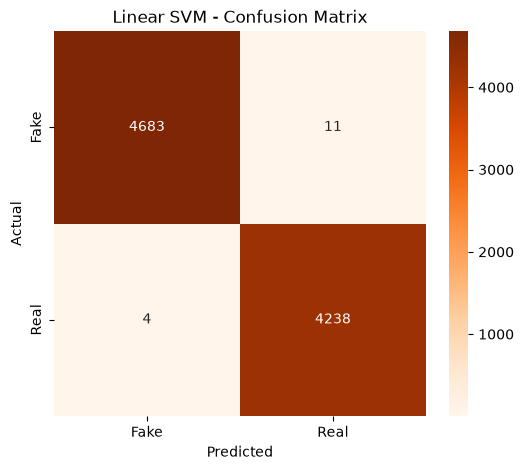

In [15]:
cm_svm = confusion_matrix(
    y_test,
    svm_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

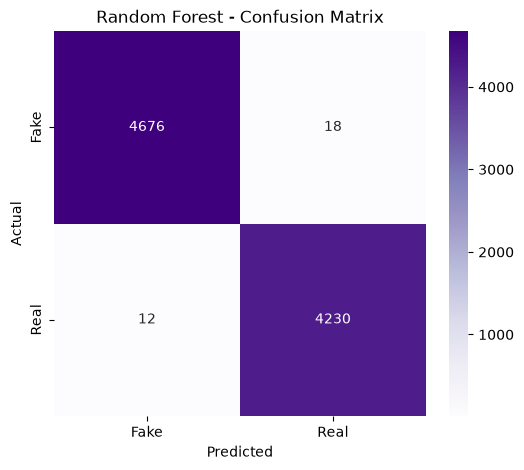

In [16]:
cm_rf = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

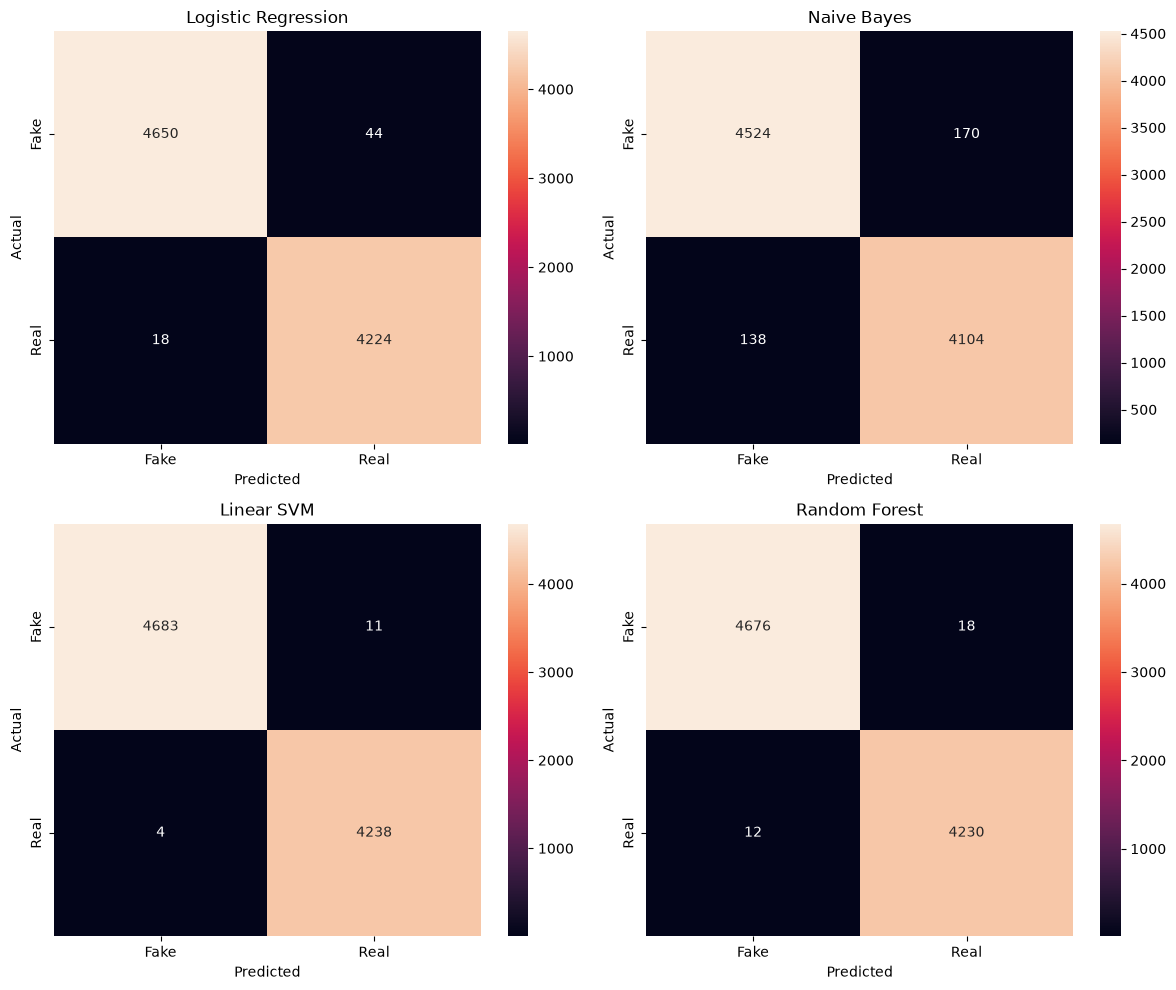

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

matrices = [
    (cm_lr, "Logistic Regression"),
    (cm_nb, "Naive Bayes"),
    (cm_svm, "Linear SVM"),
    (cm_rf, "Random Forest")
]

for ax, (cm, title) in zip(axes.ravel(), matrices):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        xticklabels=["Fake", "Real"],
        yticklabels=["Fake", "Real"]
    )
    
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [18]:
lr_prob = lr_model.predict_proba(
    X_test_tfidf
)[:, 1]

nb_prob = nb_model.predict_proba(
    X_test_tfidf
)[:, 1]

rf_prob = rf_model.predict_proba(
    X_test_tfidf
)[:, 1]

svm_score = svm_model.decision_function(
    X_test_tfidf
)

In [19]:
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    lr_prob
)

fpr_nb, tpr_nb, _ = roc_curve(
    y_test,
    nb_prob
)

fpr_svm, tpr_svm, _ = roc_curve(
    y_test,
    svm_score
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_prob
)

In [20]:
auc_lr = auc(fpr_lr, tpr_lr)
auc_nb = auc(fpr_nb, tpr_nb)
auc_svm = auc(fpr_svm, tpr_svm)
auc_rf = auc(fpr_rf, tpr_rf)

print("Logistic Regression AUC:", round(auc_lr, 4))
print("Naive Bayes AUC:", round(auc_nb, 4))
print("Linear SVM AUC:", round(auc_svm, 4))
print("Random Forest AUC:", round(auc_rf, 4))

Logistic Regression AUC: 0.9997
Naive Bayes AUC: 0.9936
Linear SVM AUC: 1.0
Random Forest AUC: 0.9997


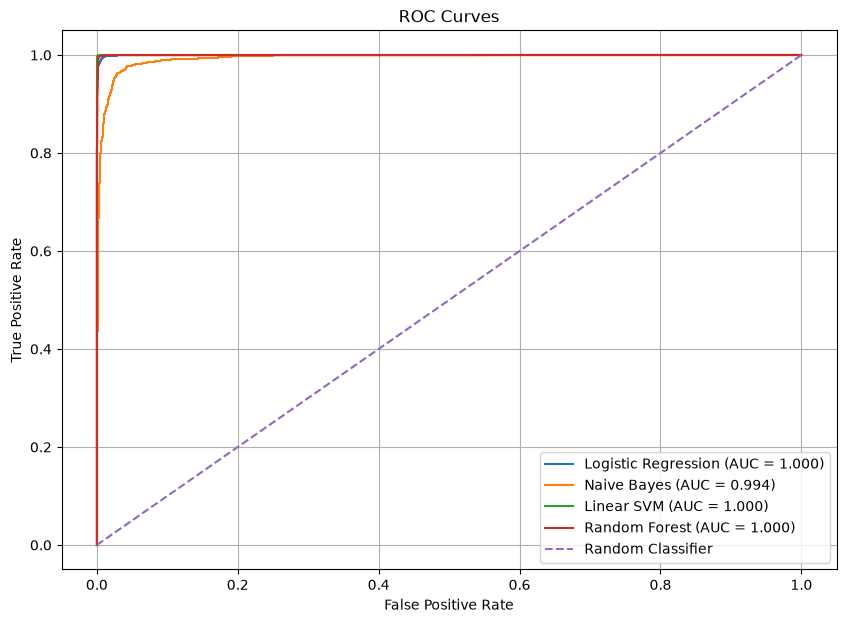

In [21]:
plt.figure(figsize=(10, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.3f})"
)

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f"Naive Bayes (AUC = {auc_nb:.3f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"Linear SVM (AUC = {auc_svm:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid()

plt.show()

In [22]:
evaluation_results["ROC-AUC"] = [
    auc_lr,
    auc_nb,
    auc_svm,
    auc_rf
]

evaluation_results = evaluation_results.round(4)

evaluation_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9931,0.9897,0.9958,0.9927,0.9997
1,Naive Bayes,0.9655,0.9602,0.9675,0.9638,0.9936
2,Linear SVM,0.9983,0.9974,0.9991,0.9982,1.0000
3,Random Forest,0.9966,0.9958,0.9972,0.9965,0.9997


In [23]:
evaluation_results.to_csv(
    "../model/final_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [24]:
error_analysis = test_data.copy()

error_analysis["prediction"] = lr_predictions

error_analysis["correct"] = (
    error_analysis["label"] ==
    error_analysis["prediction"]
)

In [25]:
errors = error_analysis[
    error_analysis["correct"] == False
]

print("Total incorrect predictions:", len(errors))

Total incorrect predictions: 62


In [26]:
errors.head(10)

,text,label,prediction,correct
305,waiting green card indian visaholders see hope...,1,0,False
667,highest glass ceiling remains intact clinton s...,1,0,False
1140,loony california secession group proclaims the...,0,1,False
1146,trump washington foreign policy speech reuters...,1,0,False
1202,yale tack new fee onto already outrageous tuit...,0,1,False
1515,new school offer education salvation syrian gi...,1,0,False
1539,kidding pa college cancel play author object u...,0,1,False
1645,factbox carlos danger got tangled clinton emai...,1,0,False
1836,breaking trump reportedly considering ted cruz...,0,1,False
1980,house take measure impeach irs chief stubborn ...,0,1,False


In [27]:
if len(errors) > 0:
    sample_error = errors.iloc[0]

    print("ACTUAL LABEL:")
    print(
        "Fake" if sample_error["label"] == 0
        else "Real"
    )

    print("\nPREDICTED LABEL:")
    print(
        "Fake" if sample_error["prediction"] == 0
        else "Real"
    )

    print("\nARTICLE:")
    print(sample_error["text"])

ACTUAL LABEL:
Real

PREDICTED LABEL:
Fake

ARTICLE:
waiting green card indian visaholders see hope trump review san francisco reuters gokul gunasekaran offered full scholarship graduate program electrical engineering stanford university saw chance lifetime grown chennai india solid job offer large oil company getting undergraduate degree came america instead got stanford degree work engineer data science startup silicon valley past five year waiting green card would give full legal right permanent resident meantime holding pattern hb visa permit live work united state allow easily switch job start company “it nobrainer came country i’m kind regretting taking scholarship” said gunasekaran also vice president nonprofit group called immigration voice represents immigrant waiting green card immigration voice estimate million hb visa holder country waiting green card many india waiting decade many immigrant welcomed president donald trump’s executive order week federal department overseeing

In [28]:
errors.to_csv(
    "../model/logistic_regression_errors.csv",
    index=False
)

print("Error analysis saved!")

Error analysis saved!
